# Jusqu'où le décodeur résiste-t-il aux erreurs ?

On abîme un QR code en recouvrant un carré de modules par un aplat rouge (qui devient noir à la binarisation), puis on regarde ce que le décodeur arrive à corriger. Le message est celui du notebook précédent ; ici on utilise le niveau de correction **M** (16 octets de correction, donc **8 octets erronés corrigeables** quand on ignore leur position) et le masque 3, avec la bibliothèque [qrcode](https://github.com/lincolnloop/python-qrcode).

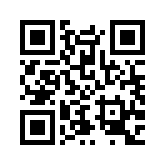

In [1]:
import numpy as np
import qrcode
from PIL import Image, ImageDraw
from qrcode.constants import ERROR_CORRECT_M
from qrcode.image.pil import PilImage
from qrcode.util import QRData

from basic_qrcode import ReedSolomonError, decode_image, qr

message = "Mon beau QR code !"
SCALE = 5  # pixels par module
BORDER = 4  # modules de zone de silence

generateur = qrcode.QRCode(
    version=2,
    error_correction=ERROR_CORRECT_M,
    box_size=SCALE,
    border=BORDER,
    mask_pattern=3,
)
generateur.add_data(QRData(message.encode(), mode=4))
generateur.make(fit=False)
original = generateur.make_image(image_factory=PilImage).convert("RGB")
original.save("../images/qrcode2.png")


def abimer(image, premier_module, cote):
    """Recouvre un carré de cote × cote modules, dont le coin haut gauche est au module
    (premier_module, premier_module) du QR code, par un aplat rouge."""
    pixels = np.array(image)
    debut = (BORDER + premier_module) * SCALE
    pixels[debut : debut + cote * SCALE, debut : debut + cote * SCALE] = [255, 0, 0]
    return Image.fromarray(pixels)


original

## Trois degrés de dégradation

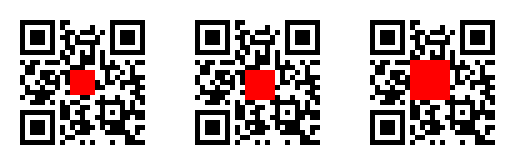

In [2]:
cas = {
    "modified_qrcode.png": (10, 5),  # carré de 5×5 modules
    "modified_qrcode2.png": (10, 6),  # carré de 6×6 modules
    "modified_qrcode3.png": (8, 8),  # carré de 8×8 modules
}
images = {}
for nom, (debut, cote) in cas.items():
    images[nom] = abimer(original, debut, cote)
    images[nom].save("../images/" + nom)

planche = Image.new("RGB", (3 * original.width + 20, original.height), "white")
for k, img in enumerate(images.values()):
    planche.paste(img, (k * (original.width + 10), 0))
planche

In [3]:
for nom, img in images.items():
    try:
        r = decode_image(img)
        print(f"{nom:22s} décodé : {r.text!r}, {len(r.corrected)} octets corrigés")
    except ReedSolomonError as e:
        print(f"{nom:22s} échec : {e}")

modified_qrcode.png    décodé : 'Mon beau QR code !', 5 octets corrigés
modified_qrcode2.png   décodé : 'Mon beau QR code !', 8 octets corrigés
modified_qrcode3.png   échec : positions des erreurs introuvables


Avec 5×5 modules, 5 octets sont corrigés ; avec 6×6, on atteint exactement la limite de 8 octets ; avec 8×8, c'est trop.

Un carré de 6×6 modules ne contient que 36 modules, soit 4,5 octets, mais il en abîme 8 : chaque octet occupe un petit rectangle de 2 colonnes sur 4 rangées (ou presque, aux changements de direction et autour des motifs de fonction), si bien qu'un carré coupe plusieurs octets à la fois. Seuls comptent les modules *changés* : un aplat noir ne modifie pas les modules déjà noirs.

## Quels octets sont touchés ?

On repère, pour chaque octet corrigé, les 8 modules qu'il occupe (en réutilisant l'astuce de l'ordre de parcours du notebook précédent), et on les entoure sur l'image.

octets corrigés : (15, 16, 21, 22, 27, 28, 33, 34)


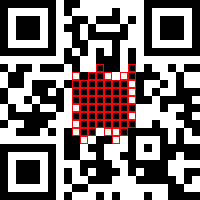

In [4]:
def octets_corriges_sur_image(image, positions, zoom=8):
    ordre = qr.read_data_bits(np.arange(qr.SIZE * qr.SIZE).reshape(qr.SIZE, qr.SIZE))
    modules = qr.image_to_modules(image)
    vue = (
        Image.fromarray(((1 - modules) * 255).astype(np.uint8))
        .resize((qr.SIZE * zoom, qr.SIZE * zoom), Image.Resampling.NEAREST)
        .convert("RGB")
    )
    dessin = ImageDraw.Draw(vue)
    for k in positions:
        for flat in ordre[8 * k : 8 * k + 8]:
            i, j = divmod(flat, qr.SIZE)
            dessin.rectangle(
                [j * zoom, i * zoom, (j + 1) * zoom - 1, (i + 1) * zoom - 1],
                outline=(255, 0, 0),
            )
    return vue


r = decode_image(images["modified_qrcode2.png"])
print("octets corrigés :", r.corrected)
octets_corriges_sur_image(images["modified_qrcode2.png"], r.corrected)

## Taille du carré et résultat

On fait varier la taille du carré, en le plaçant au même endroit. Quand OpenCV est installé, on compare avec son détecteur de QR codes, qui sert ici de décodeur indépendant.

In [5]:
try:
    import cv2
except ImportError:
    cv2 = None


def opencv_decode(image):
    assert cv2 is not None
    detecteur = cv2.QRCodeDetector()
    texte, _, _ = detecteur.detectAndDecode(
        cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    )
    return texte == message


print(f"{'côté':>5} {'octets corrigés':>16}   résultat" + ("   OpenCV" if cv2 else ""))
for cote in range(1, 10):
    img = abimer(original, 10, cote)
    try:
        n = len(decode_image(img).corrected)
        resultat, n = "décodé", str(n)
    except ReedSolomonError:
        resultat, n = "échec", "-"
    ligne = f"{cote:>5} {n:>16}   {resultat:8s}"
    if cv2:
        ligne += "   " + ("décodé" if opencv_decode(img) else "échec")
    print(ligne)

 côté  octets corrigés   résultat   OpenCV
    1                1   décodé     décodé
    2                2   décodé     décodé
    3                3   décodé     décodé
    4                4   décodé     décodé
    5                5   décodé     décodé
    6                8   décodé     décodé
    7                -   échec      échec
    8                -   échec      échec
    9                -   échec      échec


## Pour aller plus loin : les effacements

Quand on ignore où sont les erreurs, il faut deux octets de correction par octet erroné : c'est la limite de 8 pour 16. Si les positions sont **connues** (par exemple parce qu'on sait qu'une zone entière est illisible), on parle d'*effacements* et un octet de correction suffit par octet effacé : en théorie jusqu'à 16 octets au niveau M. Notre décodeur ne traite pas les effacements. La page Wikiversity citée dans le README les décrit, avec les « syndromes de Forney ».